
# African Youth Unemployment Prediction

## 1. Introduction

**Primary Grand Challenge:** Job Creation

**Secondary Grand Challenge:** Education

My mission focuses on addressing youth unemployment
across Africa by promoting job creation, improving
access to education, and supporting economic opportunities
for young people.

### Problem Statement

Youth unemployment remains a major development challenge across African economies.

Understanding how economic conditions, education,
demographic changes, and employment structures relate to youth unemployment can support better planning and decision-making.

This project uses multivariate regression to predict youth unemployment rates across African countries.

### Intended Users

The model is designed for:

- Government policymakers
- Youth employment agencies
- Development organizations and NGOs
- Labour-market researchers

These users can apply the predictions to assess
employment trends, identify countries requiring
further investigation, and support evidence-based
planning for youth employment programmes.

### Project Objective

To develop and compare four regression models
using World Bank data and select the model with
the lowest test Mean Squared Error (MSE).

The selected model will subsequently be deployed
through a FastAPI service and integrated into
a Flutter mobile application.



## 2. Dataset Description

**Dataset:** African Youth Unemployment Indicators

**Source:** World Bank, World Development Indicators (WDI)

**Geographic Coverage:** 54 African countries

**Time Period:** 2000–2024

**Target Variable:** Youth unemployment rate (%),
ages 15–24.

**World Bank Indicator:** SL.UEM.1524.ZS

**Source Link:**
https://databank.worldbank.org/source/world-development-indicators

The dataset was compiled using the World Bank API.

It combines economic, educational, demographic,
and labour-market indicators for African countries.

Each observation represents one country in one year.

The dataset contains numerical variables, including
GDP growth, inflation, education expenditure,
and employment indicators.

It also contains categorical information such as
country and income group.

The dataset uses real-world World Bank data rather
than synthetic or standard classroom datasets.


In [280]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# Set random seed
np.random.seed(42)

print("Libraries imported successfully")


Libraries imported successfully


In [281]:

# Load the World Bank dataset
df = pd.read_csv('/content/africa_youth_unemployment.csv')

df.head()


,country_code,country,region,income_group,year,youth_unemployment_rate,gdp_growth,gdp_per_capita,inflation,secondary_enrollment,education_expenditure,urban_population_pct,population_growth,agriculture_employment,industry_employment,female_labor_participation
0,DZA,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,2000,50.661,3.8,1772.928691,0.339163,64.595421,NaN,59.852124,1.399669,21.997716,24.689663,12.026
1,DZA,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,2001,46.927,3.0,1896.300209,4.225988,68.763298,NaN,60.617717,1.373291,21.717977,24.996043,12.160
2,DZA,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,2002,46.034,5.4,1937.464114,1.418302,72.583069,NaN,61.381266,1.330395,21.751301,24.776133,12.318
3,DZA,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,2003,43.862,6.5,2283.772993,4.268954,75.435867,NaN,62.142791,1.329615,21.722032,24.680837,12.503
4,DZA,Algeria,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,2004,34.211,4.5,2816.993850,3.961800,79.629860,NaN,62.902313,1.396440,21.340475,26.784539,12.713


In [282]:

# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Check geographic and time coverage
print("Countries:", df['country_code'].nunique())
print("Start year:", df['year'].min())
print("End year:", df['year'].max())


Rows: 1350
Columns: 16
Countries: 54
Start year: 2000
End year: 2024


In [283]:

# Inspect dataset structure
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1350 entries, 0 to 1349
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country_code                1350 non-null   object 
 1   country                     1350 non-null   object 
 2   region                      1350 non-null   object 
 3   income_group                1350 non-null   object 
 4   year                        1350 non-null   int64  
 5   youth_unemployment_rate     1322 non-null   float64
 6   gdp_growth                  1305 non-null   float64
 7   gdp_per_capita              1320 non-null   float64
 8   inflation                   1240 non-null   float64
 9   secondary_enrollment        737 non-null    float64
 10  education_expenditure       890 non-null    float64
 11  urban_population_pct        1350 non-null   float64
 12  population_growth           1349 non-null   float64
 13  agriculture_employment      1322 

In [284]:

# Summary statistics
df.describe()


,year,youth_unemployment_rate,gdp_growth,gdp_per_capita,inflation,secondary_enrollment,education_expenditure,urban_population_pct,population_growth,agriculture_employment,industry_employment,female_labor_participation
count,1350.000000,1322.000000,1305.000000,1320.000000,1240.000000,737.000000,890.000000,1350.000000,1349.000000,1322.000000,1322.000000,1322.000000
mean,2012.000000,17.709166,3.981900,2308.445680,10.180488,49.173747,3.948500,42.770692,2.340593,45.727002,14.177355,54.011635
std,7.213775,16.224710,6.200641,2970.100853,32.690890,25.739196,2.050836,18.070413,1.067553,21.909452,7.422777,19.153966
min,2000.000000,0.391000,-50.338515,109.593814,-16.859691,3.347850,0.000004,8.043814,-5.415910,1.190060,1.668778,12.026000
25%,2006.000000,5.588000,2.099989,580.307181,2.350193,30.262609,2.501855,29.887987,1.760685,30.527442,8.023321,42.333500
50%,2012.000000,10.186500,4.280715,1079.029985,5.047892,43.303871,3.533608,40.943394,2.465641,47.136126,13.422938,55.963000
75%,2018.000000,26.354000,6.255906,2833.404740,9.456225,72.575086,5.085129,55.196485,2.966022,64.054060,18.553648,70.764000
max,2024.000000,81.882000,86.826748,19141.511874,557.201817,122.120628,13.219570,91.863209,6.410083,91.937552,34.603552,87.825000


In [285]:

# Check missing values
df.isnull().sum()


,0
country_code,0
country,0
region,0
income_group,0
year,0
youth_unemployment_rate,28
gdp_growth,45
gdp_per_capita,30
inflation,110
secondary_enrollment,613


In [286]:

# Calculate missing percentages
missing_pct = df.isnull().mean() * 100

missing_pct.sort_values(ascending=False).round(2)


,0
secondary_enrollment,45.41
education_expenditure,34.07
inflation,8.15
gdp_growth,3.33
gdp_per_capita,2.22
agriculture_employment,2.07
youth_unemployment_rate,2.07
female_labor_participation,2.07
industry_employment,2.07
population_growth,0.07


In [287]:

# Check duplicate country-year records
df.duplicated(subset=['country_code', 'year']).sum()


np.int64(0)

In [288]:

# Check target availability
target = 'youth_unemployment_rate'

print("Total observations:", len(df))
print("Known target values:", df[target].notna().sum())
print("Missing target values:", df[target].isna().sum())


Total observations: 1350
Known target values: 1322
Missing target values: 28


In [289]:

# Identify candidate numeric features
num_features = [
    'gdp_growth',
    'gdp_per_capita',
    'inflation',
    'secondary_enrollment',
    'education_expenditure',
    'urban_population_pct',
    'population_growth',
    'agriculture_employment',
    'industry_employment',
    'female_labor_participation'
]

# Check availability where target is known
available = df[df[target].notna()]

feature_pct = available[num_features].notna().mean() * 100

feature_pct.sort_values(ascending=False).round(2)


,0
industry_employment,100.00
urban_population_pct,100.00
female_labor_participation,100.00
population_growth,100.00
agriculture_employment,100.00
gdp_per_capita,97.81
gdp_growth,96.67
inflation,91.83
education_expenditure,66.11
secondary_enrollment,53.78


In [290]:

# Eight high-coverage numeric features
base_features = [
    'gdp_growth',
    'gdp_per_capita',
    'inflation',
    'urban_population_pct',
    'population_growth',
    'agriculture_employment',
    'industry_employment',
    'female_labor_participation'
]

# Count complete observations
complete = df.dropna(subset=[target] + base_features)

print("Complete observations:", len(complete))
print("Numeric features:", len(base_features))
print("Countries:", complete['country_code'].nunique())


Complete observations: 1193
Numeric features: 8
Countries: 51



### Initial Data Quality Findings

The dataset contains 1,350 country-year observations
from 54 African countries between 2000 and 2024.

The target variable is youth unemployment rate (%).

An initial assessment shows that education-related
indicators have considerably more missing observations
than economic and labour-market indicators.

To preserve sufficient observations for modelling,
eight numeric features with relatively high data
availability have been identified as a baseline.

The education-related features will be assessed
separately to determine whether they can be retained
using appropriate missing-value handling.

Missing target values will not be imputed.


## 3. Exploratory Data Analysis

### Correlation Analysis

This heatmap examines relationships between the selected
numeric features and youth unemployment rates.

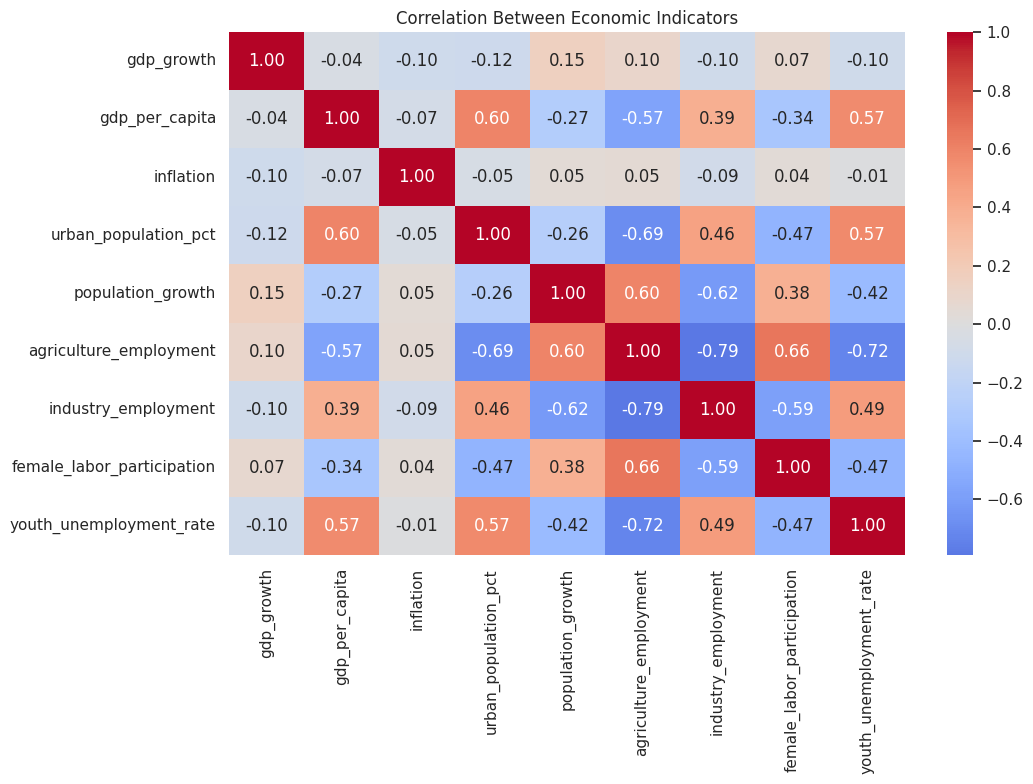

In [291]:

# Correlation matrix
corr_cols = base_features + [target]

corr = complete[corr_cols].corr()

# Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Between Economic Indicators')
plt.tight_layout()
plt.show()



### Heatmap Interpretation

Agricultural employment has the strongest negative correlation
with youth unemployment (-0.72), while GDP per capita and
urbanization have moderate positive correlations (+0.57).
The strong correlation between agricultural and industrial
employment (-0.79) also suggests potential multicollinearity.

All eight features will initially be retained for comparison,
while scaling and feature relationships will be considered
during preprocessing and model evaluation.


In [292]:

# Correlation with youth unemployment
target_corr = corr[target].drop(target)

target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)


,youth_unemployment_rate
agriculture_employment,-0.723431
urban_population_pct,0.572191
gdp_per_capita,0.566440
industry_employment,0.488088
female_labor_participation,-0.472976
population_growth,-0.419857
gdp_growth,-0.095326
inflation,-0.013096


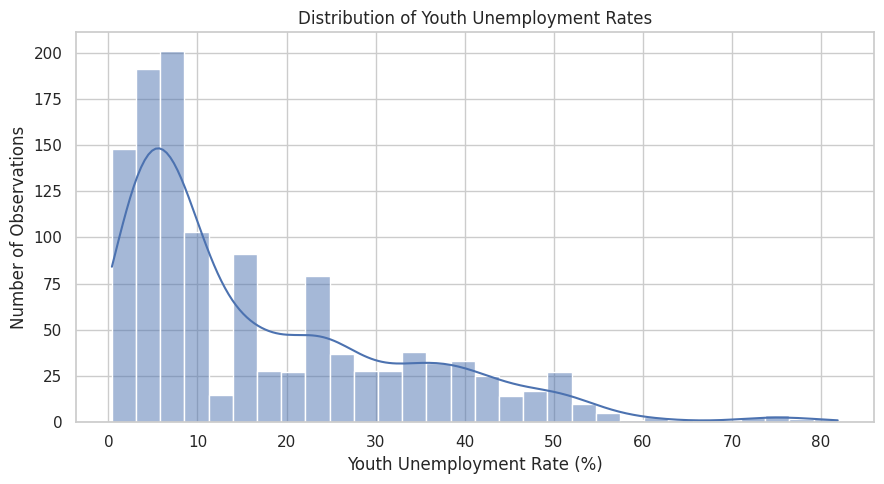

In [293]:

# Distribution of youth unemployment
plt.figure(figsize=(9, 5))

sns.histplot(
    complete[target],
    bins=30,
    kde=True
)

plt.title('Distribution of Youth Unemployment Rates')
plt.xlabel('Youth Unemployment Rate (%)')
plt.ylabel('Number of Observations')
plt.tight_layout()
plt.show()



### Distribution Interpretation

Youth unemployment rates are right-skewed, with most
observations concentrated below 15% and a long tail
extending toward 80%. This indicates considerable
differences in unemployment levels across African economies.

The target will be retained in its original percentage
scale, and model performance will be compared using MSE,
which penalizes large prediction errors more heavily.


### Relationship Between Agricultural Employment and Youth Unemployment

The following scatter plot examines the relationship between
agricultural employment and youth unemployment before fitting
a regression model.

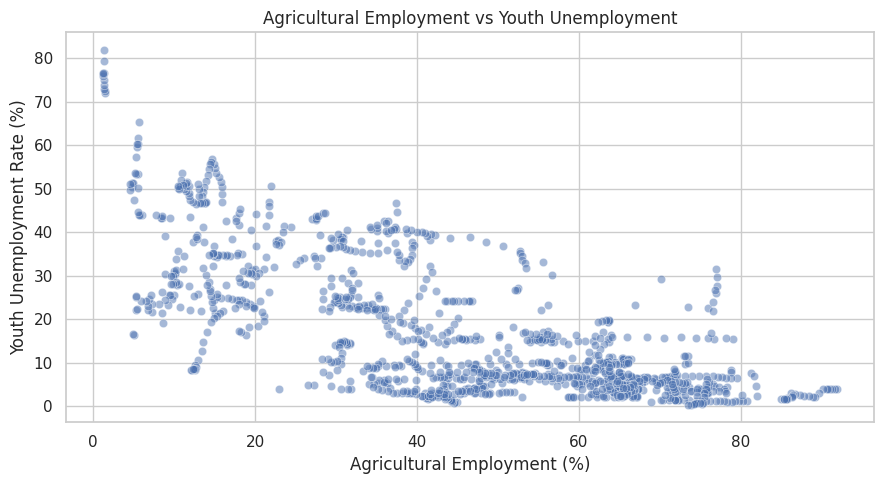

In [294]:

# Scatter plot before regression
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=complete,
    x='agriculture_employment',
    y=target,
    alpha=0.5
)

plt.title('Agricultural Employment vs Youth Unemployment')
plt.xlabel('Agricultural Employment (%)')
plt.ylabel('Youth Unemployment Rate (%)')
plt.tight_layout()
plt.show()



### Scatter Plot Interpretation

The scatter plot shows a strong negative relationship
between agricultural employment and youth unemployment.
Countries with higher agricultural employment shares
generally report lower youth unemployment rates.

However, the considerable variation between observations
suggests that agricultural employment alone cannot fully
explain unemployment differences. Multiple economic
and demographic predictors will therefore be used.


In [295]:

# Fit simple linear regression
from sklearn.linear_model import LinearRegression

X_simple = complete[['agriculture_employment']]
y_simple = complete[target]

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)

print("Slope:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)


Slope: -0.5151119301823301
Intercept: 40.48906239852877


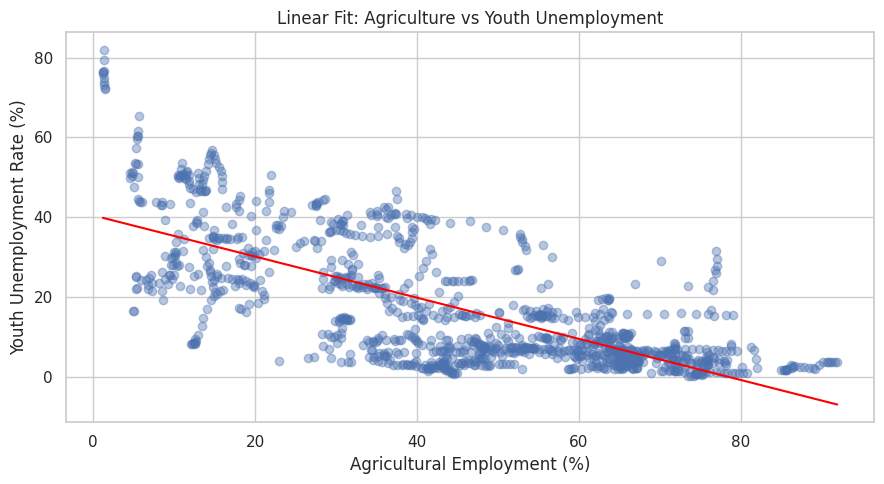

In [296]:

# Plot the fitted scikit-learn regression line
x_line = np.linspace(
    X_simple.min().iloc[0],
    X_simple.max().iloc[0],
    100
)

y_line = simple_model.predict(
    pd.DataFrame({
        'agriculture_employment': x_line
    })
)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_simple,
    y_simple,
    alpha=0.4
)

plt.plot(x_line, y_line, color='red')

plt.title('Linear Fit: Agriculture vs Youth Unemployment')
plt.xlabel('Agricultural Employment (%)')
plt.ylabel('Youth Unemployment Rate (%)')
plt.tight_layout()
plt.show()



### Regression Line Interpretation

The fitted line has a slope of -0.515 and an intercept
of 40.489, indicating a negative linear association
between agricultural employment and youth unemployment.

The scatter around the fitted line suggests that a
single-feature linear model has limited explanatory
power. Multivariate linear regression and tree-based
models will be compared to capture additional
relationships within the dataset.



## 4. Feature Engineering and Data Preprocessing

The dataset contains economic, demographic, and
labour-market indicators that may help predict
youth unemployment across African countries.

Eight numeric features were selected based on their
availability and relevance to the prediction target.

Income group was retained as a categorical feature
to represent differences in economic development.

Country names and country codes were excluded because
they are identifiers rather than direct economic
measurements. The original World Bank region column
was excluded because its broad categories provide
limited geographic detail within Africa.

Year was retained to account for changes over time.

Education expenditure and secondary enrolment were
excluded from this baseline because of substantial
missing values. Their potential contribution will
be considered separately.


In [297]:

# Select numeric features
num_cols = base_features + ['year']

# Select categorical features
cat_cols = ['income_group']

# Prepare modelling dataset
model_cols = num_cols + cat_cols + [target]

model_df = df[model_cols].dropna().copy()

print("Modelling rows:", len(model_df))
print("Numeric features:", len(num_cols))
print("Categorical features:", len(cat_cols))


Modelling rows: 1193
Numeric features: 9
Categorical features: 1


In [298]:

# Separate input features and target
X = model_df.drop(columns=[target])
y = model_df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (1193, 10)
Target shape: (1193,)



### Train and Test Split

The dataset is divided into training and testing
sets using an 80:20 ratio.

The training set will be used to fit the models,
while the test set will be used to evaluate
their predictive performance.

Preprocessing transformations will be fitted
using only the training data to prevent leakage.


In [299]:

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 954
Testing rows: 239


In [300]:

# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define preprocessing
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore'
    ), cat_cols)
])


In [301]:

# Fit preprocessing on training data only
X_train_scaled = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_scaled = preprocessor.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


Training shape: (954, 12)
Testing shape: (239, 12)


In [302]:

# Check scaling of numeric training features
scaled_num = X_train_scaled[:, :len(num_cols)]

print("Mean:", np.round(scaled_num.mean(axis=0), 2))
print("Std:", np.round(scaled_num.std(axis=0), 2))


Mean: [ 0. -0. -0. -0.  0. -0.  0.  0.  0.]
Std: [1. 1. 1. 1. 1. 1. 1. 1. 1.]



### Preprocessing Summary

Numerical features were standardized using
StandardScaler, while income group was converted
into numerical columns using one-hot encoding.

The preprocessing transformer was fitted on the
training set only and then applied to the test set,
preventing test-data leakage.

This ensures that features with different scales,
such as GDP per capita and population growth,
can be used consistently during model training.


In [303]:

# Select input features
num_cols = base_features + ['year']
cat_cols = ['income_group']

# Create modelling dataset
model_cols = num_cols + cat_cols + [target]
model_df = df[model_cols].dropna().copy()

print("Observations:", len(model_df))
print("Numeric features:", len(num_cols))
print("Categorical features:", len(cat_cols))


Observations: 1193
Numeric features: 9
Categorical features: 1


In [304]:

# Separate features and target
X = model_df.drop(columns=[target])
y = model_df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (1193, 10)
y shape: (1193,)



### Training and Testing Data

An 80:20 train-test split is used to compare all four
regression models on the same observations.

The split uses a fixed random state for reproducibility.
Preprocessing will be fitted on the training data only
to prevent information leakage into model evaluation.


In [305]:

# Split training and testing data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 954
Testing rows: 239


In [306]:

# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define numeric and categorical transformations
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore'
    ), cat_cols)
])


In [307]:

# Fit on training data only
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test data
X_test_scaled = preprocessor.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


Training shape: (954, 12)
Testing shape: (239, 12)


In [308]:

# Check standardized numeric columns
scaled_num = X_train_scaled[:, :len(num_cols)]

print("Means:", np.round(scaled_num.mean(axis=0), 2))
print("Standard deviations:",
      np.round(scaled_num.std(axis=0), 2))


Means: [ 0. -0. -0. -0.  0. -0.  0.  0.  0.]
Standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1.]



### Preprocessing Summary

Nine numeric features were standardized using
StandardScaler, while income group was encoded
using OneHotEncoder.

The preprocessing transformer was fitted only
on the training data and applied unchanged to
the test data to prevent data leakage.

The same transformations will be included in the
saved model pipeline for API predictions.



## 5. Training and Comparing Regression Models

Four regression algorithms are evaluated using the
same training and testing datasets:

1. SGDRegressor
2. LinearRegression
3. DecisionTreeRegressor
4. RandomForestRegressor

Mean Squared Error (MSE) is used to evaluate
prediction accuracy. Lower MSE indicates better
performance.

Both training and testing MSE are recorded to
compare model performance and assess overfitting.


In [309]:

# Import regression models
from sklearn.linear_model import SGDRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Import evaluation metric
from sklearn.metrics import mean_squared_error


In [310]:

# Linear regression using gradient descent
sgd = SGDRegressor(
    max_iter=1000,
    tol=1e-3,
    random_state=42
)

sgd.fit(X_train_scaled, y_train)

# Linear regression using closed-form optimization
linear = LinearRegression()
linear.fit(X_train_scaled, y_train)

print("Linear regression models trained.")


Linear regression models trained.


In [311]:

# Decision tree regression
tree = DecisionTreeRegressor(
    random_state=42
)

tree.fit(X_train_scaled, y_train)

# Random forest regression
forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest.fit(X_train_scaled, y_train)

print("Tree-based models trained.")


Tree-based models trained.


In [312]:

# Store trained models
models = {
    'SGD Regression': sgd,
    'Linear Regression': linear,
    'Decision Tree': tree,
    'Random Forest': forest
}

# Evaluate train and test MSE
results = []

for name, model in models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    results.append({
        'Model': name,
        'Train MSE': mean_squared_error(
            y_train, train_pred
        ),
        'Test MSE': mean_squared_error(
            y_test, test_pred
        )
    })

results_df = pd.DataFrame(results)
results_df.sort_values('Test MSE')


,Model,Train MSE,Test MSE
3,Random Forest,1.723289,9.515430
2,Decision Tree,0.000000,17.527452
1,Linear Regression,102.230023,84.332000
0,SGD Regression,102.369768,84.537571



### Initial Model Comparison

Random Forest achieved the lowest test MSE (9.515),
followed by Decision Tree (17.527). Both tree-based
models significantly outperformed the linear models.

Decision Tree achieved zero training MSE but a higher
test MSE, indicating overfitting. The similar results
of Linear Regression and SGD Regression suggest that
gradient descent approached the closed-form solution.

These results suggest that nonlinear relationships
between economic, demographic, and labour-market
indicators are important for predicting youth unemployment.



## 6. SGD Hyperparameter Tuning

SGDRegressor uses gradient descent to minimize
prediction error through repeated model updates.

Three hyperparameters will be investigated:

- Learning rate: controls the size of model updates.
- Alpha: controls regularization strength.
- Epochs: determines how many times the model
  processes the training dataset.

A validation set will be created from the training
data to select hyperparameters without using the
test set for optimization.

Model performance will be measured using MSE.


In [313]:

# Create training and validation sets
from sklearn.base import clone

X_sub, X_val, y_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# Fit preprocessing on the training subset only
val_preprocessor = clone(preprocessor)

X_sub_scaled = val_preprocessor.fit_transform(X_sub)
X_val_scaled = val_preprocessor.transform(X_val)

print("Training subset:", X_sub_scaled.shape)
print("Validation set:", X_val_scaled.shape)


Training subset: (763, 12)
Validation set: (191, 12)


In [314]:

# Hyperparameters to test
learning_rates = [0.001, 0.01, 0.05]
alphas = [0.0001, 0.01]
epochs_list = [50, 150, 300]

print("Learning rates:", learning_rates)
print("Alpha values:", alphas)
print("Epoch counts:", epochs_list)


Learning rates: [0.001, 0.01, 0.05]
Alpha values: [0.0001, 0.01]
Epoch counts: [50, 150, 300]


In [315]:

# Tune SGD hyperparameters
tuning_results = []

for lr in learning_rates:
    for alpha in alphas:
        model = SGDRegressor(
            learning_rate='constant',
            eta0=lr,
            alpha=alpha,
            random_state=42
        )

        for epoch in range(1, max(epochs_list) + 1):
            model.partial_fit(X_sub_scaled, y_sub)

            if epoch in epochs_list:
                pred = model.predict(X_val_scaled)
                mse = mean_squared_error(y_val, pred)

                tuning_results.append({
                    'Learning Rate': lr,
                    'Alpha': alpha,
                    'Epochs': epoch,
                    'Validation MSE': mse
                })

print("Hyperparameter tuning completed.")


Hyperparameter tuning completed.


In [316]:

# Display tuning results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    'Validation MSE'
).reset_index(drop=True)

tuning_df.head(10)


,Learning Rate,Alpha,Epochs,Validation MSE
0,0.001,0.0001,300,106.343684
1,0.001,0.0001,150,106.346538
2,0.001,0.0100,150,106.424031
3,0.001,0.0100,300,106.431324
4,0.001,0.0001,50,106.447052
5,0.001,0.0100,50,106.480300
6,0.010,0.0100,300,117.976568
7,0.010,0.0100,150,117.976581
8,0.010,0.0100,50,117.980598
9,0.010,0.0001,300,118.192210


In [317]:

# Select best hyperparameters
best_params = tuning_df.iloc[0]

best_lr = float(best_params['Learning Rate'])
best_alpha = float(best_params['Alpha'])
best_epochs = int(best_params['Epochs'])

print("Best learning rate:", best_lr)
print("Best alpha:", best_alpha)
print("Best epochs:", best_epochs)
print("Validation MSE:", best_params['Validation MSE'])


Best learning rate: 0.001
Best alpha: 0.0001
Best epochs: 300
Validation MSE: 106.34368402797347



## 7. SGD Training and Test Loss Curves

The optimized SGDRegressor is trained using
partial_fit() for the selected number of epochs.

Training and testing MSE are recorded after each
epoch to visualize the learning process.

Hyperparameters were selected using validation
data. The test loss curve is displayed only
for evaluation and is not used for tuning.


In [318]:

# Initialize optimized SGD model
sgd_tuned = SGDRegressor(
    learning_rate='constant',
    eta0=best_lr,
    alpha=best_alpha,
    random_state=42
)

train_losses = []
test_losses = []

# Train one epoch at a time
for epoch in range(best_epochs):
    sgd_tuned.partial_fit(X_train_scaled, y_train)

    train_pred = sgd_tuned.predict(X_train_scaled)
    test_pred = sgd_tuned.predict(X_test_scaled)

    train_losses.append(
        mean_squared_error(y_train, train_pred)
    )

    test_losses.append(
        mean_squared_error(y_test, test_pred)
    )

print("Final Train MSE:", round(train_losses[-1], 4))
print("Final Test MSE:", round(test_losses[-1], 4))


Final Train MSE: 102.3189
Final Test MSE: 84.2538


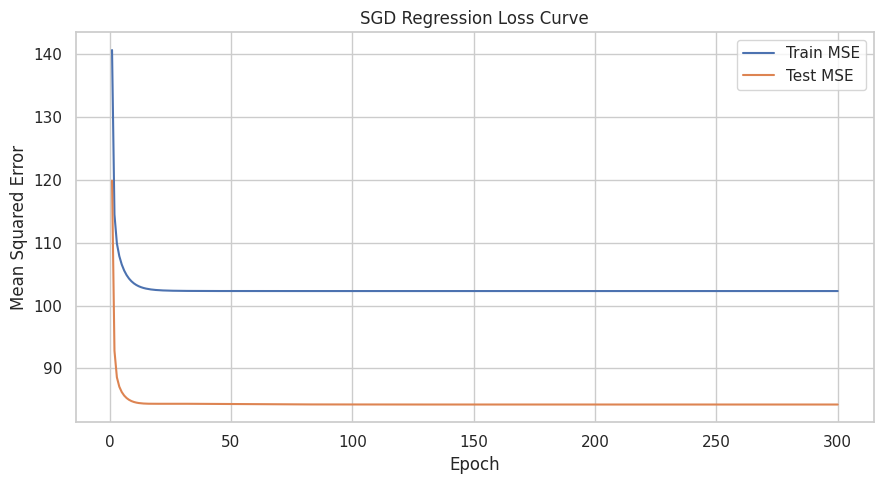

In [319]:

# Plot SGD training and testing loss
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, best_epochs + 1),
    train_losses,
    label='Train MSE'
)

plt.plot(
    range(1, best_epochs + 1),
    test_losses,
    label='Test MSE'
)

plt.title('SGD Regression Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### SGD Hyperparameter Tuning Results

The best validation performance was achieved with a
learning rate of 0.001, alpha of 0.0001, and 300 epochs.
The optimized SGD model achieved a training MSE of
102.319 and a testing MSE of 84.254.

Hyperparameter tuning produced a small improvement
over the initial SGD model. However, the remaining
error suggests that linear regression cannot fully
capture the complex relationships within the dataset.



## 8. Model Robustness Testing

The initial models were evaluated using a random
80:20 train-test split.

However, the dataset contains observations from
the same African countries across multiple years.

A second evaluation uses observations from 2000–2019
for training and 2020–2024 for testing.

This helps assess how well the models generalize
to later economic conditions.

The original test set remains the primary comparison.
This additional evaluation is used to assess
robustness rather than tune hyperparameters.


In [320]:

# Split observations by year
train_time = model_df[model_df['year'] <= 2019]
test_time = model_df[model_df['year'] >= 2020]

print("Training rows:", len(train_time))
print("Testing rows:", len(test_time))


Training rows: 957
Testing rows: 236


In [321]:

# Separate features and target
X_train_time = train_time.drop(columns=[target])
y_train_time = train_time[target]

X_test_time = test_time.drop(columns=[target])
y_test_time = test_time[target]

# Fit preprocessing on earlier years only
from sklearn.base import clone

time_preprocessor = clone(preprocessor)

X_train_time_scaled = time_preprocessor.fit_transform(
    X_train_time
)

X_test_time_scaled = time_preprocessor.transform(
    X_test_time
)

print("Training shape:", X_train_time_scaled.shape)
print("Testing shape:", X_test_time_scaled.shape)


Training shape: (957, 12)
Testing shape: (236, 12)


In [322]:

# Define models for temporal testing
time_models = {
    'SGD Regression': SGDRegressor(
        learning_rate='constant',
        eta0=best_lr,
        alpha=best_alpha,
        max_iter=best_epochs,
        tol=None,
        random_state=42
    ),
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Train all four models
for model in time_models.values():
    model.fit(X_train_time_scaled, y_train_time)

print("Temporal models trained.")


Temporal models trained.


In [323]:

# Evaluate temporal models
time_results = []

for name, model in time_models.items():
    train_pred = model.predict(X_train_time_scaled)
    test_pred = model.predict(X_test_time_scaled)

    time_results.append({
        'Model': name,
        'Train MSE': mean_squared_error(
            y_train_time, train_pred
        ),
        'Test MSE': mean_squared_error(
            y_test_time, test_pred
        )
    })

time_df = pd.DataFrame(time_results)

time_df.sort_values('Test MSE')


,Model,Train MSE,Test MSE
3,Random Forest,1.181500,68.143945
2,Decision Tree,0.000000,113.750093
0,SGD Regression,89.195026,139.772469
1,Linear Regression,88.972978,141.879970



### Temporal Evaluation Interpretation

Random Forest achieved the lowest temporal test MSE
(68.144), outperforming Decision Tree (113.750),
SGD Regression (139.772), and Linear Regression
(141.880).

However, its temporal test error was substantially
higher than its random-split test MSE of 9.515.
This suggests that predicting unemployment in
later years is more difficult than predicting
randomly selected country-year observations.

The results indicate that Random Forest captures
nonlinear relationships more effectively, but its
performance may decline under changing economic
conditions. The temporal evaluation provides a
more cautious assessment of model generalization.



## 9. Evaluating Education Indicators

The baseline models excluded secondary school
enrolment and government education expenditure
because of their high missing-value percentages.

However, education is directly connected to the
project's GCGO mission of Job Creation and Education.

This experiment evaluates whether including these
indicators improves youth unemployment predictions.

Missing predictor values will be handled using
median imputation fitted on training data only.

The same training and testing observations will
be used for a fair comparison with the baseline.


In [324]:

# Select education-inclusive features
edu_num_cols = base_features + [
    'secondary_enrollment',
    'education_expenditure',
    'year'
]

edu_cat_cols = ['income_group']

print("Numeric features:", len(edu_num_cols))
print("Categorical features:", len(edu_cat_cols))


Numeric features: 11
Categorical features: 1


In [325]:

# Select matching observations
edu_cols = edu_num_cols + edu_cat_cols

X_train_edu = df.loc[X_train.index, edu_cols]
X_test_edu = df.loc[X_test.index, edu_cols]

print("Training shape:", X_train_edu.shape)
print("Testing shape:", X_test_edu.shape)


Training shape: (954, 12)
Testing shape: (239, 12)


In [326]:

# Import preprocessing tools
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numeric preprocessing
edu_num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Combined preprocessing
edu_preprocessor = ColumnTransformer([
    ('num', edu_num_pipeline, edu_num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore'
    ), edu_cat_cols)
])


In [327]:

# Create education-inclusive model
edu_forest = Pipeline([
    ('preprocessor', edu_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
edu_forest.fit(X_train_edu, y_train)

# Make predictions
edu_pred = edu_forest.predict(X_test_edu)

# Calculate test MSE
edu_mse = mean_squared_error(y_test, edu_pred)

print("Education Model MSE:", round(edu_mse, 4))


Education Model MSE: 8.2606


In [328]:

# Get baseline Random Forest MSE
base_mse = results_df.loc[
    results_df['Model'] == 'Random Forest',
    'Test MSE'
].iloc[0]

# Compare model performance
edu_results = pd.DataFrame({
    'Model': [
        'Baseline Random Forest',
        'Education Random Forest'
    ],
    'Test MSE': [
        base_mse,
        edu_mse
    ]
})

edu_results


,Model,Test MSE
0,Baseline Random Forest,9.515430
1,Education Random Forest,8.260573



### Education Feature Evaluation

The education-inclusive Random Forest achieved a
test MSE of 8.261, compared with 9.515 for the
baseline model, representing a 13.2% improvement.

This suggests that secondary school enrolment and
government education expenditure provide additional
information for predicting youth unemployment.
Including these variables also strengthens the
model's connection to the Education and Job Creation
Grand Challenges.

However, this improvement is exploratory and should
be validated further before selecting a final model.



## 10. Final Model Comparison and Selection

The education-inclusive dataset will be used to
compare all four regression algorithms.

The models will use the same training observations,
testing observations, and preprocessing steps.

Missing numeric values are handled using median
imputation, followed by standardization.

Income group is converted into numeric variables
using one-hot encoding.

The SGD model uses the hyperparameters selected
during the earlier validation experiment.

The model with the lowest test MSE will be selected
for deployment.


In [329]:

# Define final regression models
final_models = {
    'SGD Regression': SGDRegressor(
        learning_rate='constant',
        eta0=best_lr,
        alpha=best_alpha,
        max_iter=best_epochs,
        tol=None,
        random_state=42
    ),
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}


In [330]:

# Build and train model pipelines
from sklearn.base import clone

final_pipelines = {}

for name, model in final_models.items():
    pipe = Pipeline([
        ('preprocessor', clone(edu_preprocessor)),
        ('model', clone(model))
    ])

    pipe.fit(X_train_edu, y_train)

    final_pipelines[name] = pipe

print("All four models trained successfully.")


All four models trained successfully.


In [331]:

# Evaluate final model performance
final_results = []

for name, pipe in final_pipelines.items():
    train_pred = pipe.predict(X_train_edu)
    test_pred = pipe.predict(X_test_edu)

    final_results.append({
        'Model': name,
        'Train MSE': mean_squared_error(
            y_train, train_pred
        ),
        'Test MSE': mean_squared_error(
            y_test, test_pred
        )
    })

final_df = pd.DataFrame(final_results)

final_df = final_df.sort_values(
    'Test MSE'
).reset_index(drop=True)

final_df.round(4)


,Model,Train MSE,Test MSE
0,Random Forest,1.6987,8.2606
1,Decision Tree,0.0000,29.8079
2,Linear Regression,99.5750,84.2421
3,SGD Regression,99.9446,84.9887


In [332]:

# Select model with lowest test MSE
best_name = final_df.loc[0, 'Model']
best_mse = final_df.loc[0, 'Test MSE']

best_pipeline = final_pipelines[best_name]

print("Best model:", best_name)
print("Lowest test MSE:", round(best_mse, 4))
print("Test RMSE:", round(np.sqrt(best_mse), 4))


Best model: Random Forest
Lowest test MSE: 8.2606
Test RMSE: 2.8741



### Final Model Selection

Random Forest achieved the lowest test MSE (8.261)
among the four regression algorithms, followed by
Decision Tree (29.808), Linear Regression (84.242),
and SGD Regression (84.989).

Random Forest performed best because its ensemble
of decision trees can capture nonlinear relationships
and interactions between economic, education,
demographic, and employment indicators.

The individual Decision Tree achieved zero training
error but a substantially higher test error,
indicating overfitting.

Random Forest was selected for deployment because
it achieved the lowest test MSE, as required by
the assignment. Its test RMSE of 2.874 represents
approximately 2.87 percentage points of youth
unemployment.

The results should be interpreted cautiously because
the random split includes observations from the same
countries across different years.



## 11. Saving and Testing the Best Model

The best-performing regression model is saved using
joblib together with its preprocessing pipeline.

This ensures that new input data receives the same
imputation, scaling, and categorical encoding
transformations used during training.

The saved model will be loaded and tested using
one observation from the test dataset before
integration with FastAPI.


In [333]:

# Save the best model pipeline
import joblib

joblib.dump(
    best_pipeline,
    'best_model.pkl'
)

print("Best model saved successfully.")


Best model saved successfully.


In [334]:

# Load the saved model
loaded_model = joblib.load('best_model.pkl')

print("Saved model loaded successfully.")


Saved model loaded successfully.


In [335]:

# Select one observation from the test set
sample = X_test_edu.iloc[[0]]

# Predict youth unemployment
prediction = loaded_model.predict(sample)[0]

# Get actual unemployment rate
actual = y_test.iloc[0]

print("Predicted unemployment:", round(prediction, 2), "%")
print("Actual unemployment:", round(actual, 2), "%")
print("Absolute error:", round(abs(actual - prediction), 2))


Predicted unemployment: 10.34 %
Actual unemployment: 15.16 %
Absolute error: 4.82


In [336]:

# Function to load model and predict one row
def predict_unemployment(row):
    model = joblib.load('best_model.pkl')
    prediction = model.predict(row)

    return float(prediction[0])


# Test the prediction function
result = predict_unemployment(
    X_test_edu.iloc[[0]]
)

print("Predicted youth unemployment:", round(result, 2), "%")


Predicted youth unemployment: 10.34 %



### Single Observation Prediction

The saved Random Forest pipeline successfully predicted
a youth unemployment rate of 10.34%, compared with
the actual rate of 15.16%.

The absolute prediction error was 4.82 percentage
points. This demonstrates that the saved model
can be loaded and used to predict an unseen test
observation, although individual prediction errors
may exceed the overall test RMSE.


In [337]:

# Download saved model
from google.colab import files

files.download('best_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>